# Physics twin walkthrough

The **physics twin** (`services/ocp-physics-digitalTwin/`) is a standalone RF simulator.
Given a cell topology (where each antenna is, which way it points, how far it is tilted down, what
frequency it transmits on) and a dozen global radio parameters, it predicts the distribution of
signal strength (RSRP) and signal quality (SINR) that users across an estate would experience,
using the 3GPP TR 38.901 *Urban Macro* (UMa) propagation model and the TR 38.901 §7.3 sector
antenna pattern. It then answers *what-if* questions: what happens to those distributions if a
cell is tilted, or switched off?

This notebook builds and runs the engine's **actual code** cell by cell. Nothing is mocked or
simplified: the functions imported from `app.*` are the same ones the service's HTTP handlers
call. Each section first explains the mathematics and the library machinery involved, then runs
it, so a reader can see how data goes in, how the twin fits its parameters, and how a
configuration change becomes a KPI change.

**Pipeline this notebook walks through** (run the cell below to draw it):


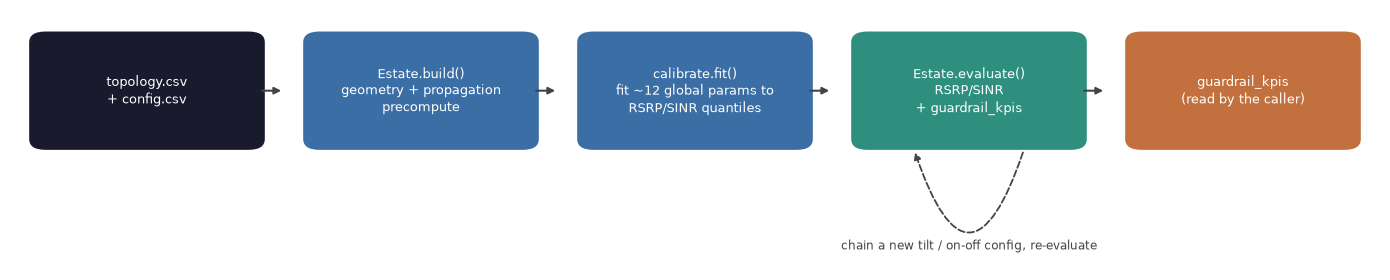

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def flow_diagram(nodes, loop=None, title=None, width=14):
    # nodes: list of (label, colour); loop: (from_idx, to_idx, label) drawn as a dashed return arrow
    n = len(nodes)
    fig, ax = plt.subplots(figsize=(width, 2.9 if loop else 2.2))
    ax.set_xlim(0, n); ax.set_ylim(-0.45 if loop else 0.1, 1.0); ax.axis("off")
    bw, bh, y = 0.82, 0.62, 0.55
    for i, (label, colour) in enumerate(nodes):
        x = i + (1 - bw) / 2
        ax.add_patch(FancyBboxPatch((x, y - bh / 2), bw, bh, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    fc=colour, ec="none"))
        ax.text(i + 0.5, y, label, ha="center", va="center", fontsize=9, color="white", linespacing=1.4)
        if i < n - 1:
            ax.annotate("", xy=(x + bw + 0.09, y), xytext=(x + bw, y),
                        arrowprops=dict(arrowstyle="-|>", color="#444", lw=1.5))
    if loop:
        a, b, label = loop
        ya = y - bh / 2
        off = 0.2 if a == b else 0.0
        ax.annotate("", xy=(b + 0.5 - off, ya - 0.02), xytext=(a + 0.5 + off, ya - 0.02),
                    arrowprops=dict(arrowstyle="-|>", color="#444", lw=1.3, ls="--",
                                    connectionstyle="arc3,rad=-1.5" if a == b else "arc3,rad=-0.45"))
        ax.text((a + b) / 2 + 0.5, ya - (0.52 if a == b else 0.30), label,
                ha="center", va="top", fontsize=8.5, color="#444")
    if title:
        ax.set_title(title, fontsize=11, loc="left")
    plt.tight_layout(); plt.show()

flow_diagram([
    ("topology.csv\n+ config.csv", "#1a1a2e"),
    ("Estate.build()\ngeometry + propagation\nprecompute", "#3a6ea5"),
    ("calibrate.fit()\nfit ~12 global params to\nRSRP/SINR quantiles", "#3a6ea5"),
    ("Estate.evaluate()\nRSRP/SINR\n+ guardrail_kpis", "#2f8f7f"),
    ("guardrail_kpis\n(read by the caller)", "#c2703d"),
], loop=(3, 3, "chain a new tilt / on-off config, re-evaluate"))

## The libraries, and why each one is here

| Library | Role in the twin |
|---|---|
| **NumPy** | The engine is *vectorised*: every quantity is a `(cells × points)` matrix, so "path loss from every cell to every grid point" is one array, and an evaluation is a handful of matrix operations rather than a loop over cells and users. `np.log10`, `np.where`, `np.argmax`, `np.percentile` do most of the physics. |
| **pandas** | Tabular I/O and bookkeeping: reading the CSV pair, merging topology with config on `cell_id`, holding the per-cell parameter table (`estate.cells`), and presenting results as DataFrames. |
| **SciPy, `scipy.optimize`** | The "training" step. `differential_evolution` is a derivative-free, population-based global optimiser; the service also runs a bounded **Nelder-Mead** polish (`minimize(method="Nelder-Mead")`). Derivative-free matters: the loss goes through an `argmax` (serving-cell choice) and `np.percentile`, both piecewise-constant in the parameters, so gradients are zero almost everywhere and gradient methods cannot be used. |
| **Matplotlib** | Plots only, the estate map, the path-loss / antenna curves, the tilt sweep and the on/off comparison. |
| **hashlib (`blake2s`)** | Inside `app.physics.propagation.rng_for`: every random draw is seeded from a hash of a name such as `"cell|g-s1-a-n3"`, so identical inputs give identical bytes on any machine. The twin is deterministic by construction. |

## What is imported from `app.*`

| Module | What it contains | Where this notebook uses it |
|---|---|---|
| `app.generic` | `generic_estate()`, a synthetic hexagonal estate generator with exactly the columns the engine needs; `default_params()`, the ~12 model parameters set to public 3GPP defaults, each reasoned in a comment; `generic_build_kwargs()`, grid-specific overrides for `Estate.build`. | Section 2 (data), Section 4 (ground truth for the calibration demo) |
| `app.physics.evaluator` | `Estate`, the model. `Estate.build()` projects coordinates, samples a grid of user positions, and precomputes path loss, LOS state, shadow fading and antenna gain for every (cell, point). `Estate.evaluate()` turns a parameter vector into RSRP/SINR distributions and KPIs. | Sections 3, 4, 5 |
| `app.physics.propagation` | `uma_los`, `uma_nlos`, `p_los_uma`, the TR 38.901 Table 7.4.1-1 / 7.4.2-1 formulas; `rng_for`, deterministic random draws. | Called inside `Estate.build`; plotted directly in Section 3 |
| `app.physics.antenna` | `gain_db`, the TR 38.901 §7.3 element pattern with explicit tilt and azimuth. | Called inside `Estate.build` and on every `tilt_override`; plotted in Section 3 |
| `app.physics.geometry` | `to_enu`, flat-earth lat/lon → metres; `cell_point_geometry`, distances and angles from one cell to every point. | Called inside `Estate.build` |
| `app.physics.calibrate` | `BOUNDS`/`NAMES`, the parameter vector and its search box; `loss()`, the quantile-matching objective; `acceptance_gate()`, the hard/soft pass criteria a fitted model must clear. | Section 4 |

**Two rungs, one engine.** Every number the twin produces carries a *rung* label saying where its
parameters came from:

| Rung | Parameters | What the numbers mean |
|---|---|---|
| `simulation, generic 3GPP defaults (uncalibrated)` | public TR 38.901 / TR 38.913 defaults | illustrative; relative comparisons only |
| `simulation, calibrated to supplied measurement data` | fitted to a locally supplied measurement report | exists only once someone has run a local calibration |

**This notebook runs entirely on the generic rung.** It needs no input data: Section 2
generates a fictional estate. For the calibration path, see the [service README](../README.md).

**Setup:** `pip install -r requirements.txt -r notebooks/requirements-notebook.txt` from the
`services/ocp-physics-digitalTwin/` directory, then run all cells top to bottom (~30 s total, mostly the calibration
cell).

## 1. Setup

The engine's modules are imported directly, no HTTP layer, no server. `sys.path` gets the
service directory (the parent of `notebooks/`) so `app.*` resolves the same way it does
when the service runs with `PYTHONPATH=$(pwd)`.

Line by line:

- `generic_estate, generic_build_kwargs, default_params, band_label`, the no-data estate
  generator and its public-default parameter set.
- `Estate`, the model class: geometry cache + evaluation.
- `loss, NAMES, BOUNDS, acceptance_gate`, the calibration objective, the parameter vector
  layout, its search box, and the pass/fail criteria.
- `uma_los, uma_nlos, p_los_uma` and `gain_db`, imported only so Section 3 can *plot* the
  propagation and antenna equations; `Estate` calls them internally regardless.
- `differential_evolution`, SciPy's global optimiser, used in Section 4.

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # the service directory, so `app.*` imports resolve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

from app.generic import generic_estate, generic_build_kwargs, default_params, band_label
from app.physics.evaluator import Estate, NOISE_DBM_RE, OUTAGE_SINR_DB, COVERAGE_RSRP_DBM
from app.physics.calibrate import loss, NAMES, BOUNDS, acceptance_gate
from app.physics.propagation import uma_los, uma_nlos, p_los_uma, SIGMA_LOS, SIGMA_NLOS
from app.physics.antenna import gain_db, peak_gain_dbi

INK, COBALT, COPPER, TEAL = "#1a1a2e", "#3a6ea5", "#c2703d", "#2f8f7f"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                      "font.size": 10, "axes.edgecolor": "#444", "axes.grid": True,
                      "grid.alpha": 0.25})
print("engine modules loaded ok")
print(f"thermal noise per resource element: {NOISE_DBM_RE:.1f} dBm  "
      f"(= -174 + 10·log10(15 kHz) + 7 dB noise figure)")

engine modules loaded ok
thermal noise per resource element: -125.2 dBm  (= -174 + 10·log10(15 kHz) + 7 dB noise figure)


## 2. Load the estate data

### What the twin needs to know about each cell

The whole model is driven by one table with a row per cell. `Estate.build()` merges the two CSVs
on `cell_id` and refuses to proceed if any of the required columns has a null, a defaulted tilt
or azimuth would produce a confident model of an antenna that does not exist.

| Column | Meaning | Used for |
|---|---|---|
| `cell_id` | unique identifier | joins, overrides, serving-share reporting |
| `cell_lat`, `cell_lon` | antenna position (degrees) | projected to east/north metres (Section 3) |
| `cell_az_deg` | sector azimuth, 0° = North, clockwise | horizontal antenna pattern $\phi$ |
| `cell_el_deg` (from `config.csv`) | electrical downtilt, degrees, positive = down | vertical antenna pattern $\theta$, **the control knob for tilt optimisation** |
| `hTx` | antenna height above ground, metres | path loss and depression angle |
| `cell_carrier_freq_mhz` | downlink carrier frequency | path loss ($20\log_{10} f_c$ term) and the band group that picks $P_0$ |
| `beam_width_deg` | horizontal 3 dB beamwidth | horizontal pattern width $\phi_{3dB}$ |
| `technology` | `NR` / `LTE` | only NR cells may *serve* in calibration (the measurement targets describe the NR leg); all cells interfere |

Topology (static) and config (tunable, `cell_el_deg`) are separate files because
the *config* is what a what-if changes; the topology never does.

### Where this notebook's data comes from

In calibration mode the twin loads a `topology.csv` + `config.csv` pair that you supply
locally (`/v1/load-local` or `/v1/upload`).

This notebook uses the **same CSV shape**, generated by the no-data generator in
`app/generic.py` and saved under an `example_` name so it is unmistakably fictional.
`generic_estate()` places sites on a hexagonal grid with inter-site distance 500 m (the
TR 38.913 UMa assumption), three 120° sectors per site at azimuths 0°/120°/240°, and one cell per
band per sector. Grid positions are converted to latitude/longitude by inverting the flat-earth
projection, around $(0°, 0°)$, a point in the open ocean, so the geometry can never be mistaken
for a real deployment.

In [3]:
topology, config = generic_estate(n_sites=3, isd_m=500.0, bands_mhz=(1800.0, 3500.0))

data_dir = pathlib.Path.cwd() / "data"
data_dir.mkdir(exist_ok=True)
topology.to_csv(data_dir / "example_topology.csv", index=False)
config.to_csv(data_dir / "example_config.csv", index=False)
print("wrote notebooks/data/example_topology.csv and notebooks/data/example_config.csv")

# Load back exactly as app.main._rebuild() does on `/v1/load-local` — CSV in, DataFrame out.
topology = pd.read_csv(data_dir / "example_topology.csv")
config = pd.read_csv(data_dir / "example_config.csv")

wrote notebooks/data/example_topology.csv and notebooks/data/example_config.csv


In [4]:
topology.head()

,cell_id,site_id,cell_lat,cell_lon,cell_az_deg,cell_carrier_freq_mhz,hTx,beam_width_deg,technology
0,g-s1-a-n3,g-s1,0.0,0.0,0.0,1800.0,30.0,65.0,NR
1,g-s1-a-n78,g-s1,0.0,0.0,0.0,3500.0,30.0,65.0,NR
2,g-s1-b-n3,g-s1,0.0,0.0,120.0,1800.0,30.0,65.0,NR
3,g-s1-b-n78,g-s1,0.0,0.0,120.0,3500.0,30.0,65.0,NR
4,g-s1-c-n3,g-s1,0.0,0.0,240.0,1800.0,30.0,65.0,NR


In [5]:
config.head()

,cell_id,cell_el_deg
0,g-s1-a-n3,6.0
1,g-s1-a-n78,6.0
2,g-s1-b-n3,6.0
3,g-s1-b-n78,6.0
4,g-s1-c-n3,6.0


3 sites × 3 sectors × 2 bands = 18 cells, ids like `g-s1-a-n3` (site 1, sector a, band n3, `band_label()` maps the carrier frequency to a 3GPP band name using the TS 38.101-1 downlink
ranges). Every cell starts at 6° electrical tilt, 30 m height, 65° beamwidth.

## 3. Build the Estate, geometry + propagation precompute

`Estate.build()` is the expensive step, and it is expensive on purpose: everything that does
**not** depend on the fitted parameters is computed once and cached, so that a calibration
search (thousands of evaluations) or an interactive what-if costs only matrix arithmetic. Here is
what it computes, in order.

### 3.1 Coordinates → metres (`geometry.to_enu`)

Latitude/longitude are projected onto a local flat East-North-Up frame centred on the estate's
mean position $(\varphi_0, \lambda_0)$, with $R_E = 6\,371\,000$ m:

$$x = (\lambda - \lambda_0)\,R_E \cos\varphi_0, \qquad y = (\varphi - \varphi_0)\,R_E$$

Accurate to about a metre over an extent of a few kilometres.

### 3.2 Where the users are (the traffic-proxy grid)

The engine does not evaluate on a uniform rectangle, that would put mass at tower bases and in
far corners no user occupies. It samples $N$ points (here 2000) uniformly *by area* in annuli
around each site, from 100 m out to $r_{\max}$ (for the hex grid, $r_{\max} = \text{ISD}/\sqrt{3}$,
the cell circumradius). Uniform-by-area means $r = \sqrt{U(100^2, r_{\max}^2)}$, not $U(100, r_{\max})$.

### 3.3 Per-(cell, point) geometry (`geometry.cell_point_geometry`)

For cell $c$ at $(x_c, y_c)$ with height $h_{BS}$ and azimuth $\alpha_c$, and point $n$ at
$(x_n, y_n)$ with user height $h_{UT} = 1.5$ m:

$$d_{2D} = \max\!\big(\sqrt{(x_n-x_c)^2 + (y_n-y_c)^2},\ 10\big), \qquad
d_{3D} = \sqrt{d_{2D}^2 + (h_{BS}-h_{UT})^2}$$

$$\phi = \operatorname{atan2}(x_n-x_c,\ y_n-y_c) - \alpha_c \ (\text{wrapped to } \pm180°), \qquad
\theta = \arctan\frac{h_{BS}-h_{UT}}{d_{2D}}$$

$\phi$ is the horizontal offset from boresight, $\theta$ the *depression* angle (positive
downward, the same sense as downtilt, so the two can be compared directly). The 10 m floor is the
TR 38.901 validity limit.

### 3.4 Line-of-sight probability (TR 38.901 Table 7.4.2-1, UMa, $h_{UT} \le 13$ m)

$$P_{LOS}(d_{2D}) = \begin{cases} 1 & d_{2D} \le 18 \text{ m} \\[4pt]
\dfrac{18}{d_{2D}} + e^{-d_{2D}/63}\Big(1 - \dfrac{18}{d_{2D}}\Big) & \text{otherwise}\end{cases}$$

Each (cell, point) pair draws a Bernoulli LOS/NLOS state from this probability. The draw is
seeded by `blake2s("cell|<cell_id>")`, so the same cell always sees the same environment.

### 3.5 Path loss (TR 38.901 Table 7.4.1-1, UMa), $f_c$ in GHz

Breakpoint distance: $d_{BP} = 4\,(h_{BS}-1)(h_{UT}-1)\,f_c \cdot 10^9 / c$.

$$PL_{LOS} = \begin{cases} 28 + 22\log_{10} d_{3D} + 20\log_{10} f_c & d_{2D} \le d_{BP} \\[4pt]
28 + 40\log_{10} d_{3D} + 20\log_{10} f_c - 9\log_{10}\!\big(d_{BP}^2 + (h_{BS}-h_{UT})^2\big) & d_{2D} > d_{BP}\end{cases}$$

$$PL_{NLOS} = \max\!\Big(PL_{LOS},\ 13.54 + 39.08\log_{10} d_{3D} + 20\log_{10} f_c - 0.6\,(h_{UT}-1.5)\Big)$$

Two things to notice: the slope steepens from 22 to 40 dB/decade past the breakpoint (ground
reflection), and NLOS is ~39 dB/decade throughout, cell edge is dominated by NLOS points.

### 3.6 Shadow fading

Large-scale fading is log-normal: a per-(cell, point) draw $z \sim \mathcal{N}(0,1)$, scaled by
$\sigma_{LOS} = 4$ dB or $\sigma_{NLOS} = 6$ dB (Table 7.4.1-1). The cache stores the *unit*
field $z\,\sigma/\sigma_{NLOS}$; at evaluation time it is multiplied by
$(\sigma_{NLOS} + \sigma_{\text{extra}})$, so the fitted parameter `sigma_extra` can widen the
spread without recomputing anything.

### 3.7 Antenna gain (TR 38.901 §7.3, `antenna.gain_db`)

With vertical/horizontal 3 dB beamwidths $\theta_{3dB} = 6.5°$, $\phi_{3dB}$ (65° here), tilt
$\tau$, and side-lobe limits $SLA_V = A_{\max} = 30$ dB:

$$A_V(\theta) = -\min\!\Big(12\Big(\frac{\theta-\tau}{\theta_{3dB}}\Big)^2,\ SLA_V\Big), \qquad
A_H(\phi) = -\min\!\Big(12\Big(\frac{\phi}{\phi_{3dB}}\Big)^2,\ A_{\max}\Big)$$

$$G(\theta,\phi) = G_{\max} - \min\!\big(-(A_V + A_H),\ A_{\max}\big), \qquad
G_{\max} = 10\log_{10}\frac{41000}{\theta_{3dB}\,\phi_{3dB}}$$

The vertical lobe is a parabola in $(\theta - \tau)$: **changing tilt slides the lobe up or
down the depression axis**, that is the entire mechanism by which a tilt change alters
coverage. The gain is cached at the baseline tilt; a `tilt_override` recomputes just the affected
cell's row using the cached $\theta, \phi$.

### 3.8 The wrap-around tier

A handful of modelled sites would sit in an unrealistically quiet RF environment. The engine adds
six translated copies of the whole estate at offsets $d_{\text{wrap}}$ along $0°, 60°, \ldots, 300°$
(for the hex grid $d_{\text{wrap}} = \sqrt{n}\cdot\text{ISD}$, an exact tiling). Tier cells
*interfere* but never *serve*, and tilt overrides never touch them, because the surroundings are
not ours to tune. Their path loss, gain and shadowing are cached like everything else.

`generic_build_kwargs()` supplies the two grid-specific values above ($d_{\text{wrap}}$ and
$r_{\max}$) as additive overrides; the calibrated path derives them from the supplied geometry.

In [6]:
build_kwargs = generic_build_kwargs(n_sites=3, isd_m=500.0)
estate = Estate.build(topology, config, n_points=2000, **build_kwargs)
serving_mask = estate.nr_serving_mask()

C, N = len(estate.cells), len(estate.grid_x)
print(f"{C} cells, {N} traffic-proxy points, {int(serving_mask.sum())} eligible to serve")
print("cached fields (shape):", {k: v.shape for k, v in estate.fields.items() if v.ndim == 2})
estate.cells[["cell_id", "x", "y", "az_deg", "tilt_deg", "freq_mhz", "grp"]].head()

18 cells, 2000 traffic-proxy points, 18 eligible to serve
cached fields (shape): {'pl': (18, 2000), 'sf_unit': (18, 2000), 'theta': (18, 2000), 'phi': (18, 2000), 'gain0': (18, 2000), 'ext_pl': (108, 2000), 'ext_gain': (108, 2000), 'ext_sf': (108, 2000)}


,cell_id,x,y,az_deg,tilt_deg,freq_mhz,grp
0,g-s1-a-n3,-250.0,-144.337567,0.0,6.0,1800.0,1
1,g-s1-a-n78,-250.0,-144.337567,0.0,6.0,3500.0,2
2,g-s1-b-n3,-250.0,-144.337567,120.0,6.0,1800.0,1
3,g-s1-b-n78,-250.0,-144.337567,120.0,6.0,3500.0,2
4,g-s1-c-n3,-250.0,-144.337567,240.0,6.0,1800.0,1


`pl`, `sf_unit`, `theta`, `phi`, `gain0` are the $(C \times N)$ matrices from §3.3 to 3.7; the
`ext_*` arrays are the $(6C \times N)$ wrap-around tier. `grp` is the band group
(0 = below 1 GHz, 1 = 1 to 3 GHz, 2 = above 3 GHz) that selects which $P_0$ a cell uses.

### 3.9 The equations, plotted

Before building on them, here are §3.5 and §3.7 evaluated directly from the imported functions,
for this estate's two carriers and a 30 m antenna.

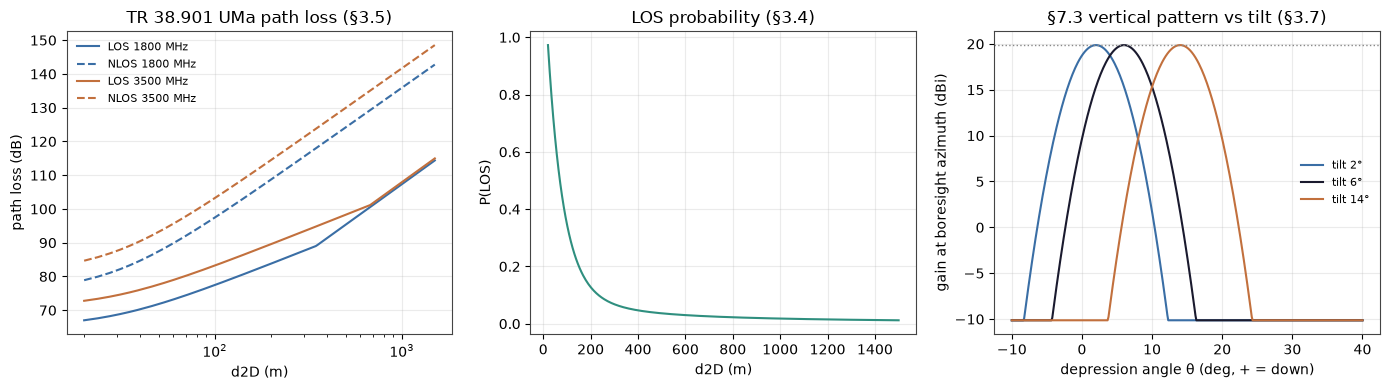

In [7]:
d2d = np.linspace(20, 1500, 400)
h_bs, h_ut = 30.0, 1.5
d3d = np.hypot(d2d, h_bs - h_ut)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))

for fc_mhz, color in ((1800.0, COBALT), (3500.0, COPPER)):
    fc = fc_mhz / 1000.0
    ax1.plot(d2d, uma_los(d2d, d3d, fc, h_bs, h_ut), color=color, label=f"LOS {int(fc_mhz)} MHz")
    ax1.plot(d2d, uma_nlos(d2d, d3d, fc, h_bs, h_ut), "--", color=color, label=f"NLOS {int(fc_mhz)} MHz")
ax1.set_xscale("log"); ax1.set_xlabel("d2D (m)"); ax1.set_ylabel("path loss (dB)")
ax1.set_title("TR 38.901 UMa path loss (§3.5)"); ax1.legend(frameon=False, fontsize=8)

ax2.plot(d2d, p_los_uma(d2d), color=TEAL)
ax2.set_xlabel("d2D (m)"); ax2.set_ylabel("P(LOS)"); ax2.set_title("LOS probability (§3.4)")

theta = np.linspace(-10, 40, 400)
for tilt, color in ((2.0, COBALT), (6.0, INK), (14.0, COPPER)):
    ax3.plot(theta, gain_db(theta, 0.0, tilt, 65.0), color=color, label=f"tilt {tilt:g}°")
ax3.axhline(peak_gain_dbi(6.5, 65.0), ls=":", color="#888", lw=1)
ax3.set_xlabel("depression angle θ (deg, + = down)"); ax3.set_ylabel("gain at boresight azimuth (dBi)")
ax3.set_title("§7.3 vertical pattern vs tilt (§3.7)"); ax3.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Left: NLOS loss runs ~15 to 20 dB above LOS at cell edge, and 3.5 GHz costs $20\log_{10}(3.5/1.8) \approx 5.8$ dB
more than 1.8 GHz everywhere. Middle: beyond ~200 m almost every point is NLOS. Right: the
vertical lobe is a parabola centred on the tilt angle, a point at depression angle 5° (roughly
330 m out from a 30 m mast) sits near peak gain at 6° tilt but ~14 dB down at 14° tilt.

### Estate map

A top-down view of the generated hex grid: site markers, one arrow per cell pointing along its
sector azimuth, coloured by band. This is the geometry the cached fields were computed over.

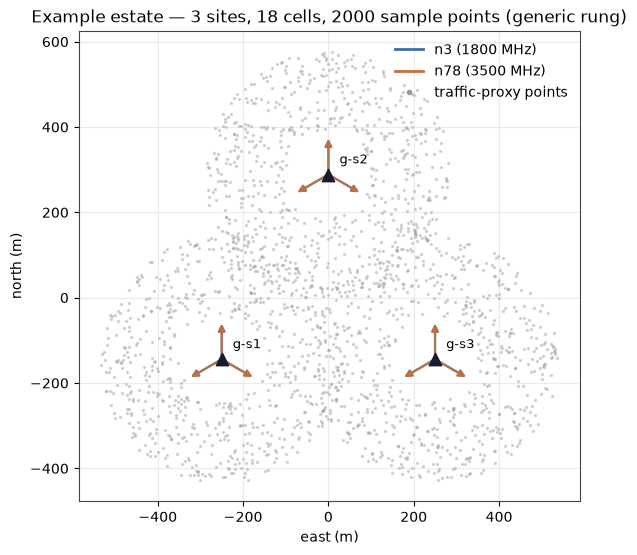

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
band_color = {b: c for b, c in zip(sorted(estate.cells.freq_mhz.unique()), [COBALT, COPPER])}

for _, c in estate.cells.iterrows():
    az = np.radians(c.az_deg)
    dx, dy = 90 * np.sin(az), 90 * np.cos(az)
    ax.annotate("", xy=(c.x + dx, c.y + dy), xytext=(c.x, c.y),
                arrowprops=dict(arrowstyle="-|>", color=band_color[c.freq_mhz], lw=1.6, alpha=0.85))

site_xy = estate.cells.groupby(estate.cells.cell_id.str.extract(r"(g-s\d+)")[0])[["x", "y"]].first()
ax.scatter(site_xy.x, site_xy.y, c=INK, s=80, zorder=5, marker="^")
for site_id, row in site_xy.iterrows():
    ax.annotate(site_id, (row.x, row.y), textcoords="offset points", xytext=(8, 8), fontsize=9)
ax.scatter(estate.grid_x, estate.grid_y, s=2, c="#999", alpha=0.35, zorder=1, label="traffic-proxy points")

handles = [plt.Line2D([0], [0], color=c, lw=2, label=f"{band_label(b)} ({int(b)} MHz)")
           for b, c in band_color.items()]
handles.append(plt.Line2D([0], [0], marker=".", color="#999", lw=0, label="traffic-proxy points"))
ax.legend(handles=handles, loc="upper right", frameon=False)
ax.set_aspect("equal"); ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
ax.set_title("Example estate — 3 sites, 18 cells, 2000 sample points (generic rung)")
plt.tight_layout(); plt.show()

## 4. Core logic, calibration ("training")

### 4.1 The forward model: from parameters to RSRP and SINR

Everything cached in Section 3 is parameter-free. The **model parameters**, the vector the
calibration fits, enter only in `Estate.evaluate()`. For cell $c$ and point $n$:

$$\mathrm{RSRP}_{c,n} = P_0[g_c] + G_{c,n} - PL_{c,n} - z_{c,n}\,(\sigma_{NLOS} + \sigma_{\text{extra}}) - \mathbb{1}[\text{indoor}_n]\,\big(L_{tw}[g_c] + 4\,z^{O2I}_n\big)$$

- $P_0[g]$, conducted power per resource element for band group $g$ (`p0_low`, `p0_mid`, `p0_hi`).
  The §7.3 peak gain is inside $G$, so $P_0 + G_{\max}$ is the boresight EIRP per RE.
- $\text{indoor}_n = (u_n < p_{in})$, a cached uniform draw compared with the fitted indoor
  fraction `p_in`; indoor points pay an outdoor-to-indoor wall loss `ltw_low` / `ltw_hi`
  (TR 38.901 §7.4.3) plus a $\pm 4$ dB per-building spread.

**Serving cell.** Each point attaches to the cell with the highest *biased* RSRP among cells that
are switched on and allowed to serve:

$$s(n) = \arg\max_{c\ \in\ \text{eligible}} \big(\mathrm{RSRP}_{c,n} + b[g_c]\big), \qquad b = (0,\ \text{bias\_mid},\ \text{bias\_hi})$$

The bias exists because NSA serving is a *policy*, not max-RSRP: a capacity-preferred band wins
even when a low-band cell is slightly stronger. The *reported* RSRP is still the chosen cell's
true, unbiased value.

**SINR.** Interference comes from every other switched-on cell on the same carrier, scaled by the
fitted average PRB load $\ell$, plus the wrap-around tier scaled by its visibility $w_{\text{tier}}$,
plus thermal noise $N_0 = -174 + 10\log_{10}(15\,000) + 7 \approx -125.2$ dBm per RE:

$$\mathrm{SINR}_n = \frac{10^{\mathrm{RSRP}_{s(n),n}/10}}
{\ell \displaystyle\sum_{\substack{c \ne s(n)\\ f_c = f_{s(n)}}} 10^{\mathrm{RSRP}_{c,n}/10}
\;+\; \ell\, w_{\text{tier}} \displaystyle\sum_{\substack{e \in \text{tier}\\ f_e = f_{s(n)}}} 10^{\mathrm{RSRP}_{e,n}/10}
\;+\; 10^{N_0/10}}$$

**The measurement operator.** A measurement report lists per-*device* session averages,
not per-point samples, and averaging along a device's day compresses the spread. The parameter
`agg` groups points into pseudo-devices of that size and averages in dB, then clamps SINR to the
reporting tool's $[-15, 23]$ dB range. This is `aggregate=True`, the *device-mean* view the
acceptance gate is judged on. `aggregate=False` skips both, the *point-sample* physical field,
which Section 5 uses for the tilt sweep. On the generic rung `agg = 1`, so the two views differ
only by the clamp.

### 4.2 What "training" means here

There are no labelled points. The engine's *structure* comes from the standard; calibration only
anchors the ~12 global unknowns by matching **marginal distributions**: the 5th/25th/50th/75th/95th
percentiles of RSRP and of SINR, ten numbers in total. The objective (`calibrate.loss`) is a
weighted squared error on those quantiles:

$$\mathcal{L}(\boldsymbol\theta) = \sum_{q} w^{R}_q \big(Q^{\text{pred}}_{R,q}(\boldsymbol\theta) - Q^{\text{target}}_{R,q}\big)^2
\;+\; 2\sum_{q} w^{S}_q \big(Q^{\text{pred}}_{S,q}(\boldsymbol\theta) - Q^{\text{target}}_{S,q}\big)^2$$

with $q \in \{5, 25, 50, 75, 95\}$, $w^R = (2,1,1,1,1)$, $w^S = (3,1,1,1,1)$. The extra weight on
the 5th percentiles is declared, not hidden: the guardrail KPIs read the cell-edge tail,
so that is where the fit is asked to be most accurate.

**Why differential evolution.** $\mathcal{L}$ is evaluated through an `argmax` and `np.percentile`,
so it is piecewise-constant with respect to $\boldsymbol\theta$, flat almost everywhere, with
jumps where a point changes serving cell or a quantile crosses a sample. Gradients are useless.
`scipy.optimize.differential_evolution` needs none: it keeps a *population* of candidate vectors
inside `BOUNDS` and, each generation, builds a trial for every member $x_i$ by mutation and
crossover,

$$v = x_a + F\,(x_b - x_c), \qquad u_j = \begin{cases} v_j & \text{with probability } CR \\ x_{i,j} & \text{otherwise}\end{cases}$$

keeping $u$ if $\mathcal{L}(u) < \mathcal{L}(x_i)$. It is robust to the flat, multi-modal
landscape at the price of many evaluations, which is exactly why Section 3 cached everything.
With `popsize=10` and 12 parameters the population is 120 vectors; `maxiter=60` bounds the run at
~7 200 loss evaluations. The service uses `maxiter=140, popsize=14` and then a bounded
Nelder-Mead polish (`calibrate.fit`); this notebook inlines the DE stage only, so the mechanics
are visible and the cell runs in seconds.

### 4.3 The parameter vector

| Name | Meaning | Bounds |
|---|---|---|
| `p0_low`, `p0_mid`, `p0_hi` | conducted power per RE, dBm, per band group | 8 to 28 |
| `sigma_extra` | extra shadowing σ on top of the 4/6 dB spec values, dB | 0 to 6 |
| `p_in` | fraction of users indoors | 0.30 to 0.995 |
| `ltw_low`, `ltw_hi` | outdoor-to-indoor wall loss, dB, low/mid vs C-band | 5 to 20, 10 to 30 |
| `load` | average PRB load of interfering cells (fraction) | 0.02 to 0.60 |
| `agg` | pseudo-device session size (measurement operator) | 1 to 24 |
| `bias_mid`, `bias_hi` | NSA band-priority serving bias, dB | 0 to 20 |
| `w_tier` | visibility of the wrap-around tier | 0 to 1 |

The $P_0$ bounds *are* the physical window: with wider bounds a search can satisfy every
quantile target by pushing one $P_0$ to an unphysical EIRP. Constraining power forces the
optimiser to explain the targets with geometry and environment instead.

### 4.4 The acceptance gate

A fitted model is only allowed into a decision path if it clears the **hard** checks; **soft**
checks are reported alongside, never hidden:

| Check | Rule | Hard? |
|---|---|---|
| RSRP median | $\lvert Q^{\text{pred}}_{R,50} - Q^{\text{target}}_{R,50}\rvert \le 2$ dB | yes |
| SINR cell edge | $\lvert Q^{\text{pred}}_{S,5} - Q^{\text{target}}_{S,5}\rvert \le 1.5$ dB | yes |
| EIRP sanity | $25 \le P_0[g] + 17 \le 45$ dBm for every band group | yes |
| RSRP tails | p5, p95 within 3 dB | no |
| SINR p50, p95 | within 2 dB | no |

### 4.5 This notebook's demo

There is no measurement report here, so the targets are **generated by the engine itself**:
evaluate a known parameter set (the public defaults) over the example estate, take its ten
quantiles as if they were a supplied report, then fit *blind* to those targets. The question the
cells below answer is the same one any calibration is held to, *does the search find a model
that reproduces the targets and passes the gate?*, not *does it recover the exact true values*.
Those are different questions: ten quantile constraints cannot pin down twelve parameters, and
several combinations (say, higher $P_0$ with more indoor loss) produce nearly the same marginals.
That non-identifiability is precisely why the gate includes a physical-plausibility check and not
only statistical ones.

In [9]:
true_params = default_params()  # the "ground truth" for this demo only — public 3GPP defaults
pd.Series(true_params, name="true (3GPP defaults)").to_frame().T

,p0_low,p0_mid,p0_hi,sigma_extra,p_in,ltw_low,ltw_hi,load,agg,bias_mid,bias_hi,w_tier
true (3GPP defaults),12.2,12.2,14.8,0.0,0.8,12.0,27.0,0.5,1.0,0.0,0.0,1.0


In [10]:
QS = [5, 25, 50, 75, 95]
ref = estate.evaluate(true_params, serving_mask=serving_mask)  # aggregate=True: device-mean, report-comparable
targets = {
    "rsrp": [round(float(v), 2) for v in np.percentile(ref["_arrays"]["rsrp"], QS)],
    "sinr": [round(float(v), 2) for v in np.percentile(ref["_arrays"]["sinr"], QS)],
}
pd.DataFrame(targets, index=[f"p{q}" for q in QS]).T

,p5,p25,p50,p75,p95
rsrp,-102.54,-93.75,-86.34,-77.44,-61.14
sinr,-15.00,-1.57,4.50,12.87,23.00


These ten numbers, and only these, are what the optimiser sees. `loss()` will call
`estate.evaluate()` for each candidate vector, take the same ten percentiles of the result, and
score the squared distance to this table.

In [11]:
%%time
bounds = [BOUNDS[n] for n in NAMES]
de = differential_evolution(loss, bounds, args=(estate, targets, serving_mask),
                            seed=7, maxiter=60, popsize=10, tol=1e-4, polish=False)
fitted_params = dict(zip(NAMES, [float(v) for v in de.x]))
print(f"DE loss: {de.fun:.4f}   generations run: {de.nit}   loss evaluations: {de.nfev}")

DE loss: 0.0525   generations run: 60   loss evaluations: 7320
CPU times: user 19.2 s, sys: 257 ms, total: 19.5 s
Wall time: 19.7 s


In [12]:
pred = estate.evaluate(fitted_params, serving_mask=serving_mask)
predicted = {
    "rsrp": [round(float(v), 2) for v in np.percentile(pred["_arrays"]["rsrp"], QS)],
    "sinr": [round(float(v), 2) for v in np.percentile(pred["_arrays"]["sinr"], QS)],
}
report = {"params": fitted_params,
          "quantiles": {"rsrp": {"predicted": predicted["rsrp"], "target": targets["rsrp"]},
                        "sinr": {"predicted": predicted["sinr"], "target": targets["sinr"]}}}
gate = acceptance_gate(report)

print(f"hard_pass: {gate['hard_pass']}\n")
pd.DataFrame(gate["checks"]).T

hard_pass: True



,delta_db,pass,hard
rsrp_p50_within_2db,0.08,True,True
sinr_p05_within_1p5db,0.0,True,True
eirp_sanity_window,NaN,True,True
rsrp_p05_within_3db,0.07,True,False
rsrp_p95_within_3db,0.07,True,False
sinr_p50_within_2db,0.01,True,False
sinr_p95_within_2db,0.0,True,False


In [13]:
pd.DataFrame({"true (3GPP defaults)": true_params, "fitted": fitted_params}).round(3)

,true (3GPP defaults),fitted
p0_low,12.2,16.468
p0_mid,12.2,10.377
p0_hi,14.8,15.512
sigma_extra,0.0,0.230
p_in,0.8,0.802
ltw_low,12.0,9.975
ltw_hi,27.0,29.652
load,0.5,0.493
agg,1.0,1.167
bias_mid,0.0,4.687


`hard_pass: True`: the fitted model clears the gate, median RSRP and cell-edge SINR within
budget, implied EIRP inside the physical window. The parameter comparison shows the
non-identifiability described in §4.5: several fitted values differ from the "true" ones while
the quantiles match, because those parameters trade off against each other in the marginals. On
the calibrated rung, the same limitation is why the service also validates against a *held-out*
device split, reproducing marginals you fit to is necessary, not sufficient.

`fitted_params` is now "the model" the rest of this notebook does inference with, standing in
for what `/v1/train` would persist as `var/model.json` in calibrated mode.

## 5. Core logic, inference, and chaining a cell config

### 5.1 What an evaluation returns

`Estate.evaluate(params, ...)` runs the forward model of §4.1 once and summarises the result as
`guardrail_kpis`, the vocabulary a caller such as the energy-saving rApp reads:

| KPI | Definition |
|---|---|
| `rsrp_p5`, `rsrp_p50`, `rsrp_p95` | percentiles of serving-cell RSRP over the sample (dBm) |
| `sinr_p5`, `sinr_p50`, `sinr_p95` | percentiles of SINR (dB); `sinr_p5` is *cell-edge quality* |
| `outage_rate` | $P(\mathrm{SINR} < -6 \text{ dB})$, points that cannot sustain a link |
| `coverage_rate` | $P(\mathrm{RSRP} > -110 \text{ dBm})$, points inside the coverage footprint |
| `serving_share` | fraction of points attached to each cell, where the traffic lands |

### 5.2 How a config change enters the model

Two overrides, both applied *without* touching the cache:

- `tilt_override={cell_id: τ'}`, recomputes only that cell's gain row,
  $G_{c,n} = G(\theta_{c,n}, \phi_{c,n};\ \tau')$, from the cached angles (§3.7). Every other row,
  and all path loss and fading, is reused. Changing the tilt of one cell therefore costs one
  vectorised pattern evaluation, not a rebuild.
- `off_cells={cell_id, ...}`, sets the cell's *active* flag false. An inactive cell is removed
  from the serving `argmax` **and** its term is dropped from the interference sum in §4.1. Points
  it was serving re-attach to the next-best eligible cell; points it was interfering with see a
  cleaner channel.

"Chaining a cell config" below means exactly that: call `evaluate()` again with a different
override and compare, a tilt sweep (a sequence of configs on one cell) and an on/off switch (the
same knob a rApp's cell-sleep action drives). Nothing is re-fit; the same `fitted_params` are used
throughout, which is what makes the comparison fair: *same model, same points, same draws,
different configuration*.

In [14]:
baseline = estate.evaluate(fitted_params, serving_mask=serving_mask)["guardrail_kpis"]
pd.Series(baseline, name="baseline").to_frame()

,baseline
rsrp_p5,-102.466032
rsrp_p50,-86.419380
rsrp_p95,-61.212970
sinr_p5,-15.000000
sinr_p50,4.487097
sinr_p95,23.000000
outage_rate,0.148500
coverage_rate,0.995500
samples,2000.000000


### 5a. Tilt sweep

Re-evaluate the *same* estate and parameters while chaining a sequence of `tilt_override` configs
on one cell. `aggregate=False` selects the point-sample view: the device-mean view of §4.1
averages several points into a pseudo-device and blunts a single cell's response, so an
optimiser comparing tilts must read the unclamped physical field.

In [15]:
sweep_cell = "g-s2-a-n78"
tilts = [2, 6, 10, 14, 18, 22]
rows = []
for t in tilts:
    r = estate.evaluate(fitted_params, tilt_override={sweep_cell: t},
                        serving_mask=serving_mask, aggregate=False)
    rows.append({"tilt_deg": t, **r["guardrail_kpis"],
                 "own_share": r["serving_share"].get(sweep_cell, 0.0)})
sweep = pd.DataFrame(rows)
sweep

,tilt_deg,rsrp_p5,rsrp_p50,rsrp_p95,sinr_p5,sinr_p50,sinr_p95,outage_rate,coverage_rate,samples,own_share
0,2,-102.498897,-86.467502,-61.274714,-15.015070,4.381411,27.433967,0.1490,0.9955,2000.0,0.0060
1,6,-102.466032,-86.419380,-61.212970,-15.015070,4.487097,27.955000,0.1485,0.9955,2000.0,0.0190
2,10,-102.370230,-86.401641,-61.076828,-15.015070,4.567577,28.114346,0.1475,0.9955,2000.0,0.0225
3,14,-102.439657,-86.439211,-61.087484,-15.044738,4.452512,27.955000,0.1490,0.9955,2000.0,0.0165
4,18,-102.466032,-86.486309,-61.193694,-15.106126,4.392688,27.132619,0.1495,0.9955,2000.0,0.0085
5,22,-102.498897,-86.543277,-61.274714,-15.106126,4.304045,27.132619,0.1510,0.9955,2000.0,0.0030


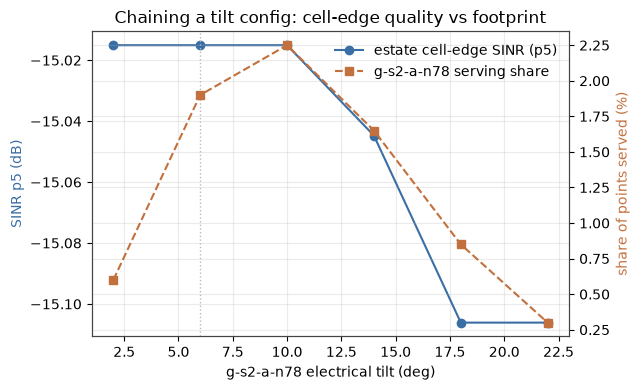

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(sweep.tilt_deg, sweep.sinr_p5, "o-", color=COBALT, label="estate cell-edge SINR (p5)")
ax2 = ax.twinx()
ax2.plot(sweep.tilt_deg, 100 * sweep.own_share, "s--", color=COPPER, label=f"{sweep_cell} serving share")
ax.axvline(6, color="#bbb", lw=1, ls=":")
ax.set_xlabel(f"{sweep_cell} electrical tilt (deg)")
ax.set_ylabel("SINR p5 (dB)", color=COBALT); ax2.set_ylabel("share of points served (%)", color=COPPER)
ax.set_title("Chaining a tilt config: cell-edge quality vs footprint")
lines = ax.get_lines()[:1] + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="best", frameon=False)
plt.tight_layout(); plt.show()

Read this with §3.7 in mind. The vertical lobe is a parabola centred on the tilt angle, and
the served area sits at depression angles of roughly 3 to 10° from a 30 m mast. At 2° the lobe
points *over* that area, gain at the users is down the side of the parabola and the cell barely
serves anyone. At 22° it points at the mast base, and again the served area is off-peak. In
between there is an optimum (here around 6 to 10°) where both the cell's own footprint (`own_share`)
and the estate's cell-edge SINR peak: the beam lands on the users and the energy that would have
spilled into neighbouring cells' edges stays home. The estate-level `sinr_p5` moves by fractions
of a dB for a *single* cell in an 18-cell estate, the right order of magnitude, and exactly the
trade a tilt-optimisation rApp negotiates across many cells at once. The response is smooth and
has a maximum, which is what makes tilt an optimisable knob at all.

### 5b. Switching a cell off

The same chaining pattern with `off_cells` instead of `tilt_override`, the knob an energy-saving
rApp's guardrail check exercises before it lets a cell go to sleep: evaluate with the candidate
cell off, compare against baseline, only actuate if the guardrails still hold.

In [17]:
sleep_cell = "g-s2-b-n3"
awake = estate.evaluate(fitted_params, serving_mask=serving_mask)
asleep = estate.evaluate(fitted_params, off_cells={sleep_cell}, serving_mask=serving_mask)

compare = pd.DataFrame({"awake (baseline)": awake["guardrail_kpis"],
                        f"{sleep_cell} asleep": asleep["guardrail_kpis"]})
compare["delta"] = compare.iloc[:, 1] - compare.iloc[:, 0]
compare

,awake (baseline),g-s2-b-n3 asleep,delta
rsrp_p5,-102.466032,-103.857801,-1.391769
rsrp_p50,-86.419380,-87.137580,-0.718200
rsrp_p95,-61.212970,-61.890487,-0.677516
sinr_p5,-15.000000,-15.000000,0.000000
sinr_p50,4.487097,4.372259,-0.114838
sinr_p95,23.000000,23.000000,0.000000
outage_rate,0.148500,0.161500,0.013000
coverage_rate,0.995500,0.992500,-0.003000
samples,2000.000000,2000.000000,0.000000


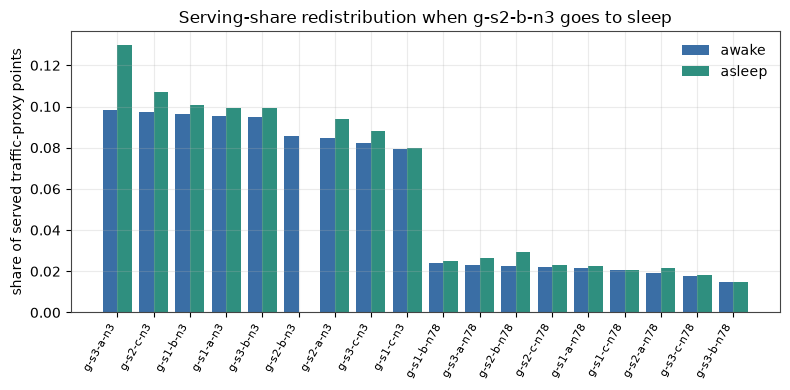

In [18]:
share_before = pd.Series(awake["serving_share"], name="awake")
share_after = pd.Series(asleep["serving_share"], name="asleep").reindex(share_before.index).fillna(0)
shares = pd.concat([share_before, share_after], axis=1).sort_values("awake", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(shares))
ax.bar(x - 0.2, shares["awake"], width=0.4, color=COBALT, label="awake")
ax.bar(x + 0.2, shares["asleep"], width=0.4, color=TEAL, label="asleep")
ax.set_xticks(x); ax.set_xticklabels(shares.index, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("share of served traffic-proxy points")
ax.set_title(f"Serving-share redistribution when {sleep_cell} goes to sleep")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

The points `g-s2-b-n3` was serving re-attach via the §4.1 `argmax` to the next-best
eligible cell, the co-sited 3.5 GHz cell on the same sector, the neighbouring sectors, or the
adjacent site on the same band, at a lower RSRP than before (hence `rsrp_p5` drops: those
points are now further from their server). The sleeping cell also leaves the interference sum,
so its 1800 MHz neighbours see a cleaner channel, which is why the SINR percentiles move far
less than the RSRP ones. `outage_rate` ticks up by about a percentage point and `coverage_rate`
slips fractionally. A guardrail check reads exactly this
`delta` column: if `sinr_p5` or `coverage_rate` had fallen past its floor, the rApp would
refuse the sleep action rather than actuate it.

## 6. Recap

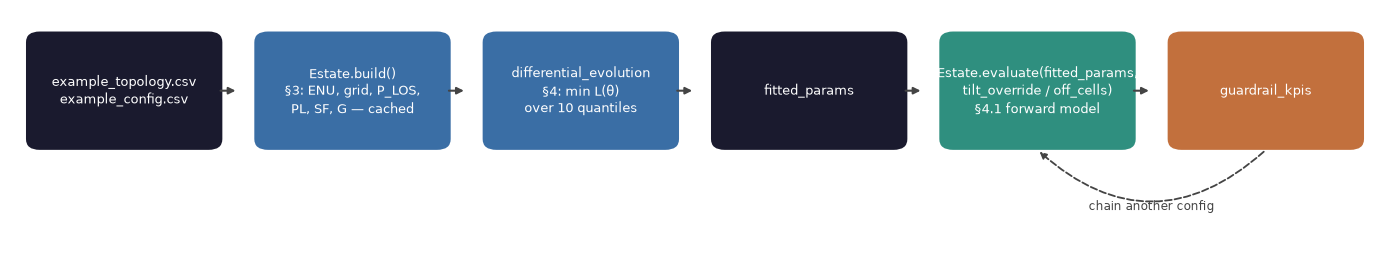

In [19]:
flow_diagram([
    ("example_topology.csv\nexample_config.csv", INK),
    ("Estate.build()\n§3: ENU, grid, P_LOS,\nPL, SF, G — cached", COBALT),
    ("differential_evolution\n§4: min L(θ)\nover 10 quantiles", COBALT),
    ("fitted_params", INK),
    ("Estate.evaluate(fitted_params,\ntilt_override / off_cells)\n§4.1 forward model", TEAL),
    ("guardrail_kpis", COPPER),
], loop=(5, 4, "chain another config"))

- **Section 2** generated a fictional example estate in the CSV shape the service loads.
- **Section 3** computed, once, everything the standard says about this geometry: TR 38.901 UMa
  path loss and LOS probability, log-normal shadowing, the §7.3 antenna pattern, and a
  wrap-around tier, all as $(C \times N)$ NumPy matrices, all deterministic.
- **Section 4** ran the actual calibration search, SciPy's `differential_evolution` over the
  same bounded 12-vector, the same quantile loss and the same acceptance gate
  `app/physics/calibrate.py` uses, and it passed the hard gates, while also showing why matching
  marginals does not pin down every parameter.
- **Section 5** showed the one function, `Estate.evaluate()`, that answers every "what if"
  question the twin is asked: change a tilt (one gain row recomputed), change which cells are on
  (one active flag flipped), read the new `guardrail_kpis`. That is the entire inference surface a
  caller uses.

Every number in this notebook carries the **generic** rung, `simulation, generic 3GPP defaults
(uncalibrated)`: public defaults, not fitted to anything. For the calibration path, see the
[service README](../README.md).